In [ ]:
`from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
base_path = "/content/drive/MyDrive/medical_dataset"
print(os.listdir(base_path))

['BBox_List_2017.csv', 'Data_Entry_2017.csv', 'LOG_CHESTXRAY.pdf', 'FAQ_CHESTXRAY.pdf', 'README_CHESTXRAY.pdf', 'train_val_list.txt', 'test_list.txt', 'images_001', 'images_002', 'images_003', 'images_004', 'images_005', 'images_006', 'images_007', 'images_008', 'images_009', 'images_010', 'images_011', 'images_012']


In [ ]:
import pandas as pd

csv_path = f"{base_path}/Data_Entry_2017.csv"
print("CSV exists:", os.path.exists(csv_path))

df = pd.read_csv(csv_path)
print("Shape:", df.shape)           # (112120, 12)
print("Columns:", df.columns.tolist())
print(df["Finding Labels"].head(10))

CSV exists: True
Shape: (112120, 12)
Columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']
0              Cardiomegaly
1    Cardiomegaly|Emphysema
2     Cardiomegaly|Effusion
3                No Finding
4                    Hernia
5                    Hernia
6                    Hernia
7       Hernia|Infiltration
8                    Hernia
9                    Hernia
Name: Finding Labels, dtype: object


In [ ]:
image_paths = {}

for i in range(1, 13):
    folder      = f"images_{str(i).zfill(3)}"
    folder_path = os.path.join(base_path, folder, "images")
    if not os.path.exists(folder_path):
        print(f"⚠ Missing: {folder_path}")
        continue
    for img in os.listdir(folder_path):
        image_paths[img] = os.path.join(folder_path, img)

df["image_path"] = df["Image Index"].map(image_paths)

print("Unmapped images:", df["image_path"].isnull().sum())  # should be 0
df = df.dropna(subset=["image_path"])   # drop any unmapped rows
print("Usable rows:", len(df))

Unmapped images: 0
Usable rows: 112120


In [ ]:
import numpy as np

all_labels = sorted(set(l for x in df["Finding Labels"] for l in x.split("|")))
print("Classes:", all_labels)
print("Total classes:", len(all_labels))   # 15

label2idx = {l: i for i, l in enumerate(all_labels)}

def encode_labels(label_str):
    vec = np.zeros(len(all_labels))
    for l in label_str.split("|"):
        vec[label2idx[l]] = 1
    return vec

df["encoded"] = df["Finding Labels"].apply(encode_labels)
print(df[["Finding Labels", "encoded"]].head())

Classes: ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'No Finding', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']
Total classes: 15
           Finding Labels                                            encoded
0            Cardiomegaly  [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
1  Cardiomegaly|Emphysema  [0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, ...
2   Cardiomegaly|Effusion  [0.0, 1.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, ...
3              No Finding  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
4                  Hernia  [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, ...


In [ ]:
from sklearn.model_selection import train_test_split

df = df.sample(n=15000, random_state=42)

train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42)
val_df,   test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Train: 12000 | Val: 1500 | Test: 1500


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# ✅ Augmentation only for training
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

class XrayDataset(Dataset):
    def __init__(self, df, transform):
        self.df        = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)
        label = torch.tensor(row["encoded"], dtype=torch.float32)
        return image, label

train_dataset = XrayDataset(train_df, train_transform)
val_dataset   = XrayDataset(val_df,   val_transform)
test_dataset  = XrayDataset(test_df,  val_transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=16, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

# Quick sanity check
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)   # [16, 3, 224, 224]
print("Label batch shape:", labels.shape)   # [16, 15]

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16, 15])


In [ ]:
!pip install timm -q

import timm
import torch.nn as nn
import torch.optim as optim

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)   # should print: cuda

# ✅ dropout added to reduce overfitting
model = timm.create_model(
    "efficientnet_b2",
    pretrained=True,
    num_classes=len(all_labels),
    drop_rate=0.3,
    drop_path_rate=0.2
)
model = model.to(device)

optimizer = optim.Adam(model.parameters(), lr=1e-4)
print("Model ready ✔")


Device: cpu


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Model ready ✔


In [ ]:
label_matrix = np.stack(train_df["encoded"].values)
pos          = label_matrix.sum(axis=0)
neg          = len(label_matrix) - pos
pos_weight   = torch.tensor(neg / (pos + 1e-5), dtype=torch.float32).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print("pos_weight (first 5):", pos_weight[:5].tolist())

pos_weight (first 5): [9.058675765991211, 37.70967483520508, 24.80645179748535, 46.80876159667969, 7.450704097747803]


In [ ]:
import os
import torch

checkpoint_path = "/content/drive/MyDrive/model_checkpoint.pth"
best_model_path = "/content/drive/MyDrive/best_model.pth"

# ✅ SAFE DEFAULTS — only used if NO checkpoint exists
start_epoch   = 0
start_batch   = 0
best_val_loss = float("inf")

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2
)

if os.path.exists(checkpoint_path):
    ckpt = torch.load(checkpoint_path, map_location=device)

    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])

    if "scheduler" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler"])
        print("✔ Scheduler restored")
    else:
        print("⚠ No scheduler in checkpoint — fresh scheduler")

    batch_val     = ckpt.get("batch", -1)
    start_epoch   = ckpt["epoch"]
    start_batch   = 0 if batch_val == -1 else batch_val + 1
    best_val_loss = ckpt.get("best_val_loss", float("inf"))

    print(f"✔ Resuming from epoch {start_epoch}, batch {start_batch}")
    print(f"✔ Best val loss so far: {best_val_loss:.4f}")

    # ✅ SAFETY GUARD — stops you accidentally restarting
    if start_epoch == 0 and not os.path.exists(checkpoint_path):
        print("⚠ WARNING: Starting from epoch 0!")
    else:
        print(f"✅ CONFIRMED: Will resume from epoch {start_epoch+1}, not epoch 1")
else:
    print("No checkpoint found — starting fresh from epoch 0")

✔ Scheduler restored
✔ Resuming from epoch 14, batch 400
✔ Best val loss so far: 0.9713
✅ CONFIRMED: Will resume from epoch 15, not epoch 1


In [ ]:
from tqdm import tqdm
from sklearn.metrics import f1_score
import torch

EPOCHS     = 10
SAVE_EVERY = 100

for epoch in range(start_epoch, EPOCHS):

    # ─────────── TRAIN ───────────
    model.train()
    train_loss = 0

    loop = tqdm(
        enumerate(train_loader),
        total=len(train_loader),
        desc=f"Epoch {epoch+1}/{EPOCHS} [TRAIN]"
    )

    for batch_idx, (images, labels) in loop:

        # Skip already-trained batches when resuming mid-epoch
        if epoch == start_epoch and batch_idx < start_batch:
            continue

        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        loss    = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # ✅ gradient clipping
        optimizer.step()

        train_loss += loss.item()

        effective = (batch_idx - start_batch + 1) if epoch == start_epoch else (batch_idx + 1)
        loop.set_postfix(avg_loss=f"{train_loss / max(1, effective):.5f}")

        # Save every 100 batches
        if (batch_idx + 1) % SAVE_EVERY == 0:
            torch.save({
                "epoch":        epoch,
                "batch":        batch_idx,
                "model":        model.state_dict(),
                "optimizer":    optimizer.state_dict(),
                "scheduler":    scheduler.state_dict(),
                "best_val_loss": best_val_loss
            }, checkpoint_path)
            print(f"\n✔ Mid-epoch save at batch {batch_idx}")

    avg_train_loss = train_loss / len(train_loader)

    # ─────────── VALIDATION ───────────
    model.eval()
    val_loss      = 0
    all_probs     = []
    all_true      = []

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs  = model(images)
            loss     = criterion(outputs, labels)
            val_loss += loss.item()
            probs    = torch.sigmoid(outputs)
            all_probs.append(probs.cpu())
            all_true.append(labels.cpu())

    val_loss     /= len(val_loader)
    all_probs_np  = torch.cat(all_probs).numpy()
    all_true_np   = torch.cat(all_true).numpy()

    # ✅ Dynamic threshold search
    best_thresh, best_f1 = 0.3, 0.0
    for t in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
        preds = (all_probs_np > t).astype(float)
        f1    = f1_score(all_true_np, preds, average="micro", zero_division=0)
        if f1 > best_f1:
            best_f1, best_thresh = f1, t

    preds_best = (all_probs_np > best_thresh).astype(float)
    accuracy   = (all_true_np == preds_best).mean()

    # ─────────── PRINT RESULTS ───────────
    print(f"\n{'='*55}")
    print(f"Epoch {epoch+1}/{EPOCHS}")
    print(f"  Train Loss : {avg_train_loss:.4f}")
    print(f"  Val Loss   : {val_loss:.4f}")
    print(f"  Accuracy   : {accuracy:.4f}")
    print(f"  F1 Score   : {best_f1:.4f}  (threshold={best_thresh})")
    print(f"  LR         : {optimizer.param_groups[0]['lr']:.6f}")
    print(f"{'='*55}")

    # ✅ Step scheduler based on val loss
    scheduler.step(val_loss)

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
        print("🔥 Best model saved!")

    # End-of-epoch checkpoint
    torch.save({
        "epoch":         epoch + 1,
        "batch":         -1,
        "model":         model.state_dict(),
        "optimizer":     optimizer.state_dict(),
        "scheduler":     scheduler.state_dict(),
        "best_val_loss": best_val_loss
    }, checkpoint_path)
    print("✔ End-of-epoch checkpoint saved")

    start_batch = 0   # reset after first epoch resume

print("\n✅ Training complete!")
print(f"Best Val Loss: {best_val_loss:.4f}")
print(f"Best model saved at: {best_model_path}")




✅ Training complete!
Best Val Loss: 0.9713
Best model saved at: /content/drive/MyDrive/best_model.pth


In [ ]:
from sklearn.metrics import classification_report, roc_auc_score

# Load best model
model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()

all_probs = []
all_true  = []

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(device)
        outputs = model(images)
        probs   = torch.sigmoid(outputs)
        all_probs.append(probs.cpu())
        all_true.append(labels)

all_probs_np = torch.cat(all_probs).numpy()
all_true_np  = torch.cat(all_true).numpy()

# Final predictions at best threshold (use 0.3 default for test)
preds = (all_probs_np > 0.3).astype(float)

print("\n📊 Per-Class Report:")
print(classification_report(
    all_true_np, preds,
    target_names=all_labels,
    zero_division=0
))

# AUC per class
print("\n📈 AUC per class:")
for i, label in enumerate(all_labels):
    try:
        auc = roc_auc_score(all_true_np[:, i], all_probs_np[:, i])
        print(f"  {label:<25} AUC: {auc:.4f}")
    except Exception:
        print(f"  {label:<25} AUC: N/A (only one class in test set)")

# Overall micro F1
overall_f1 = f1_score(all_true_np, preds, average="micro", zero_division=0)
print(f"\n✅ Overall Micro F1: {overall_f1:.4f}")


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



📊 Per-Class Report:
                    precision    recall  f1-score   support

       Atelectasis       0.16      0.86      0.27       145
      Cardiomegaly       0.04      0.83      0.07        29
     Consolidation       0.07      0.89      0.14        62
             Edema       0.05      0.86      0.09        28
          Effusion       0.23      0.89      0.37       185
         Emphysema       0.05      0.65      0.09        20
          Fibrosis       0.02      0.77      0.04        22
            Hernia       0.07      0.50      0.12         2
      Infiltration       0.19      0.97      0.32       269
              Mass       0.09      0.81      0.16        88
        No Finding       0.62      0.89      0.73       828
            Nodule       0.08      0.86      0.14        87
Pleural_Thickening       0.05      0.77      0.09        44
         Pneumonia       0.02      0.65      0.04        20
      Pneumothorax       0.10      0.90      0.18        70

         micro av

In [ ]:
import numpy as np
from sklearn.metrics import f1_score, classification_report

# Reload best model
model.load_state_dict(torch.load("/content/drive/MyDrive/best_model.pth", map_location=device))
model.eval()

all_probs = []
all_true  = []

with torch.no_grad():
    for images, labels in test_loader:
        images  = images.to(device)
        outputs = model(images)
        probs   = torch.sigmoid(outputs)
        all_probs.append(probs.cpu())
        all_true.append(labels)

all_probs_np = torch.cat(all_probs).numpy()
all_true_np  = torch.cat(all_true).numpy()

# ✅ Find best threshold per class individually
print("Finding best threshold per class...\n")
best_thresholds = []

for i, label in enumerate(all_labels):
    best_t, best_f1 = 0.5, 0.0
    for t in np.arange(0.1, 0.9, 0.05):
        preds = (all_probs_np[:, i] > t).astype(float)
        if preds.sum() == 0:
            continue
        from sklearn.metrics import f1_score as f1s
        f1 = f1s(all_true_np[:, i], preds, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    best_thresholds.append(best_t)
    print(f"  {label:<25} best threshold: {best_t:.2f}  F1: {best_f1:.4f}")

# Apply per-class thresholds
final_preds = np.zeros_like(all_probs_np)
for i, t in enumerate(best_thresholds):
    final_preds[:, i] = (all_probs_np[:, i] > t).astype(float)

print("\n📊 Per-Class Report (per-class thresholds):")
print(classification_report(
    all_true_np, final_preds,
    target_names=all_labels,
    zero_division=0
))

overall_f1 = f1_score(all_true_np, final_preds, average="micro", zero_division=0)
print(f"✅ Overall Micro F1 with per-class thresholds: {overall_f1:.4f}")

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Finding best threshold per class...

  Atelectasis               best threshold: 0.60  F1: 0.3333
  Cardiomegaly              best threshold: 0.85  F1: 0.1714
  Consolidation             best threshold: 0.85  F1: 0.1835
  Edema                     best threshold: 0.85  F1: 0.1772
  Effusion                  best threshold: 0.70  F1: 0.5000
  Emphysema                 best threshold: 0.75  F1: 0.1852
  Fibrosis                  best threshold: 0.80  F1: 0.1481
  Hernia                    best threshold: 0.40  F1: 0.1818
  Infiltration              best threshold: 0.60  F1: 0.3743
  Mass                      best threshold: 0.65  F1: 0.2590
  No Finding                best threshold: 0.50  F1: 0.7439
  Nodule                    best threshold: 0.65  F1: 0.2500
  Pleural_Thickening        best threshold: 0.65  F1: 0.1818
  Pneumonia                 best threshold: 0.85  F1: 0.0625
  Pneumothorax              best threshold: 0.75  F1: 0.3131

📊 Per-Class Report (per-class thresholds):
    

In [ ]:
import json

threshold_dict = {label: float(t) for label, t in zip(all_labels, best_thresholds)}

with open("/content/drive/MyDrive/best_thresholds.json", "w") as f:
    json.dump(threshold_dict, f, indent=2)

print("✔ Thresholds saved!")

✔ Thresholds saved!


In [ ]:
import os
print(os.path.exists("/content/drive/MyDrive/best_model.pth"))      # True
print(os.path.exists("/content/drive/MyDrive/best_thresholds.json")) # True

True
True


In [ ]:
import torch
import json
import numpy as np
from PIL import Image
from torchvision import transforms

# ── Load best model ──
model.load_state_dict(torch.load(
    "/content/drive/MyDrive/best_model.pth",
    map_location=device
))
model.eval()
print("✔ Best model loaded")

# ── Load thresholds ──
with open("/content/drive/MyDrive/best_thresholds.json", "r") as f:
    threshold_dict = json.load(f)
print("✔ Thresholds loaded")
print("Thresholds:", threshold_dict)

# ── Transform for single image inference ──
infer_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])
print("✔ Setup complete — ready for agents")

✔ Best model loaded
✔ Thresholds loaded
Thresholds: {'Atelectasis': 0.6000000000000002, 'Cardiomegaly': 0.8500000000000002, 'Consolidation': 0.8500000000000002, 'Edema': 0.8500000000000002, 'Effusion': 0.7000000000000002, 'Emphysema': 0.7500000000000002, 'Fibrosis': 0.8000000000000002, 'Hernia': 0.40000000000000013, 'Infiltration': 0.6000000000000002, 'Mass': 0.6500000000000001, 'No Finding': 0.5000000000000001, 'Nodule': 0.6500000000000001, 'Pleural_Thickening': 0.6500000000000001, 'Pneumonia': 0.8500000000000002, 'Pneumothorax': 0.7500000000000002}
✔ Setup complete — ready for agents


In [ ]:
class DetectionAgent:
    """
    Agent 1 — Detection Agent
    Responsibilities:
    - Runs EfficientNet on input image
    - Applies per-class thresholds
    - Makes Normal/Abnormal decision
    - Flags low confidence predictions
    - Passes findings to Grad-CAM
    """
    def __init__(self, model, all_labels, threshold_dict, device):
        self.model          = model
        self.all_labels     = all_labels
        self.threshold_dict = threshold_dict
        self.device         = device
        self.name           = "Agent 1 - Detection Agent"

    def run(self, image_path):
        print(f"\n{'='*55}")
        print(f"[{self.name}]")
        print(f"{'='*55}")
        print(f"Analyzing image: {image_path}")

        # Step 1: Load and preprocess image
        image  = Image.open(image_path).convert("RGB")
        tensor = infer_transform(image).unsqueeze(0).to(self.device)

        # Step 2: Run EfficientNet model
        with torch.no_grad():
            outputs = self.model(tensor)
            probs   = torch.sigmoid(outputs).cpu().numpy()[0]

        # Step 3: Apply per-class thresholds
        detected     = []
        low_conf     = []
        all_findings = {}

        for i, label in enumerate(self.all_labels):
            thresh     = self.threshold_dict[label]
            confidence = float(probs[i])

            all_findings[label] = {
                "confidence": round(confidence, 4),
                "threshold":  thresh,
                "detected":   confidence >= thresh
            }

            if confidence >= thresh:
                detected.append((label, confidence))
                # Flag if confidence is just above threshold
                if confidence < thresh + 0.08:
                    low_conf.append(label)

        # Step 4: Sort by confidence
        detected.sort(key=lambda x: x[1], reverse=True)

        # Step 5: Make Normal/Abnormal decision
        non_normal = [(l, c) for l, c in detected if l != "No Finding"]

        if not non_normal:
            decision = "NORMAL"
            severity = "None"
        elif len(non_normal) == 1:
            decision = "ABNORMAL"
            severity = "Mild"
        elif len(non_normal) <= 3:
            decision = "ABNORMAL"
            severity = "Moderate"
        else:
            decision = "ABNORMAL"
            severity = "Severe"

        # Step 6: Print findings
        print(f"\nDecision : {decision}")
        print(f"Severity : {severity}")
        print(f"\nDetected Findings:")
        for label, conf in detected:
            print(f"  • {label:<25} confidence: {conf:.4f}")
        if low_conf:
            print(f"\n⚠ Low confidence flags: {low_conf}")

        print(f"\n✔ Passing findings to Grad-CAM...")

        return {
            "image_path":   image_path,
            "all_findings": all_findings,
            "detected":     detected,
            "decision":     decision,
            "severity":     severity,
            "low_conf":     low_conf,
            "raw_probs":    probs,
            "agent":        self.name
        }

# ── Initialize Agent 1 ──
detection_agent = DetectionAgent(model, all_labels, threshold_dict, device)
print("✔ Agent 1 (Detection Agent) initialized\n")

# ── Test on one sample ──
sample_image  = test_df.iloc[0]["image_path"]
result_agent1 = detection_agent.run(sample_image)

✔ Agent 1 (Detection Agent) initialized


[Agent 1 - Detection Agent]
Analyzing image: /content/drive/MyDrive/medical_dataset/images_012/images/00030279_004.png

Decision : ABNORMAL
Severity : Severe

Detected Findings:
  • Pneumonia                 confidence: 0.9172
  • Effusion                  confidence: 0.7546
  • Mass                      confidence: 0.7412
  • Infiltration              confidence: 0.6497
  • Atelectasis               confidence: 0.6299

⚠ Low confidence flags: ['Atelectasis', 'Effusion', 'Infiltration', 'Pneumonia']

✔ Passing findings to Grad-CAM...


✔ Grad-CAM Explainer initialized


[Grad-CAM Explainability Module]
  • Pneumonia                 hotspot region: middle-center | intensity: 1.0000
  • Effusion                  hotspot region: lower-right | intensity: 1.0000
  • Mass                      hotspot region: middle-right | intensity: 1.0000
  • Infiltration              hotspot region: upper-left | intensity: 1.0000
  • Atelectasis               hotspot region: middle-right | intensity: 1.0000


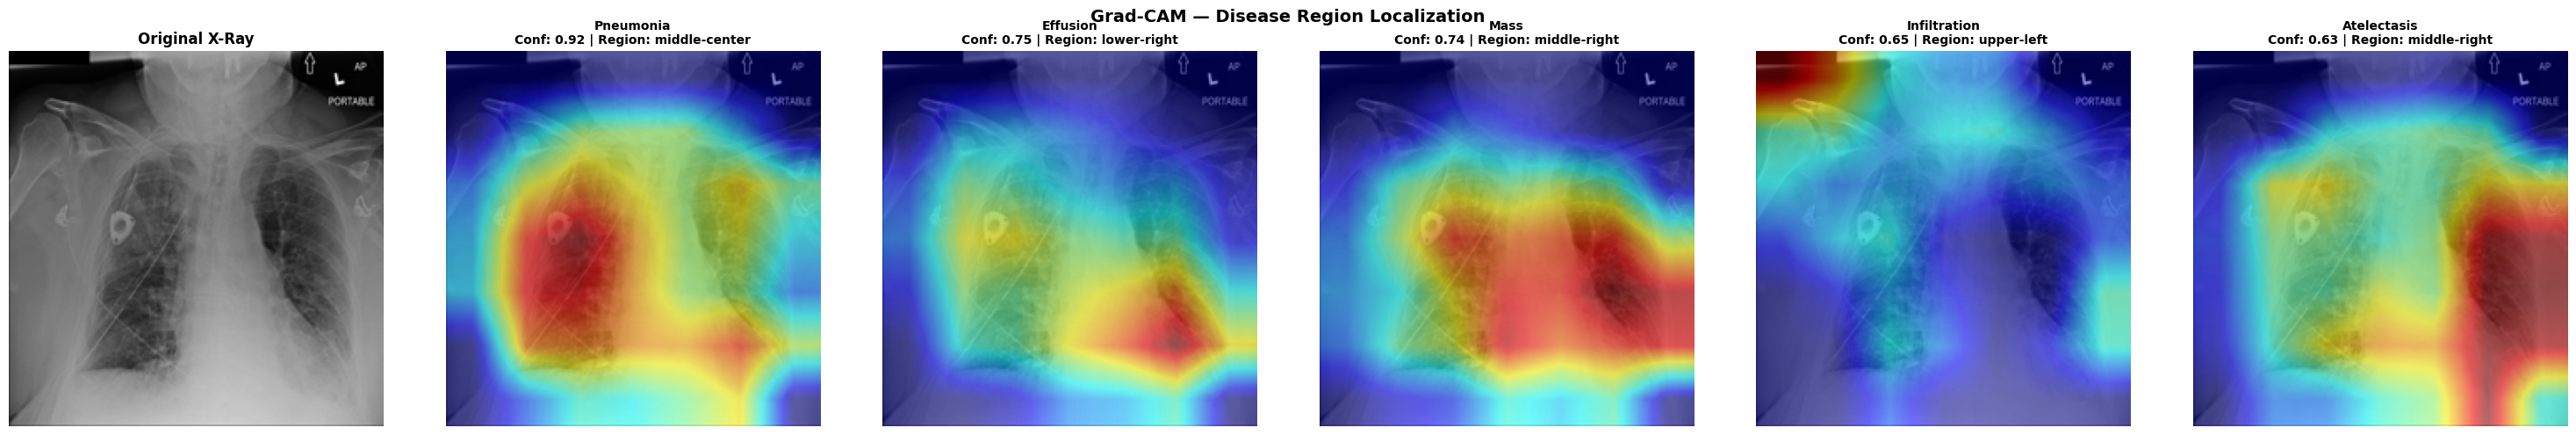


✔ Grad-CAM saved to: /content/drive/MyDrive/gradcam_output.png
✔ Passing heatmap info to Agent 2...

Heatmap Info:
  • Pneumonia                 region: middle-center | intensity: 1.0
  • Effusion                  region: lower-right | intensity: 1.0
  • Mass                      region: middle-right | intensity: 1.0
  • Infiltration              region: upper-left | intensity: 1.0
  • Atelectasis               region: middle-right | intensity: 1.0


In [ ]:
!pip install grad-cam -q

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import cv2

class GradCAMExplainer:
    """
    Grad-CAM Explainability Module
    Responsibilities:
    - Takes Agent 1 detected findings
    - Generates heatmap for each detected disease
    - Shows WHERE in the X-ray each disease was found
    - Saves annotated image to Drive
    - Passes heatmap info to Agent 2
    """
    def __init__(self, model, device):
        self.model        = model
        self.device       = device
        self.target_layer = [model.conv_head]
        self.cam          = GradCAM(
            model        = model,
            target_layers= self.target_layer
        )
        self.transform = infer_transform

    def generate(self, image_path, detected_findings):
        print(f"\n{'='*55}")
        print(f"[Grad-CAM Explainability Module]")
        print(f"{'='*55}")

        if not detected_findings:
            print("No findings to explain")
            return None

        # Filter out No Finding
        findings_to_explain = [
            (l, c) for l, c in detected_findings
            if l != "No Finding"
        ]

        if not findings_to_explain:
            print("Only No Finding detected — no heatmap needed")
            return None

        # Load original image
        orig_image = Image.open(image_path).convert("RGB")
        orig_image = orig_image.resize((224, 224))
        orig_np    = np.array(orig_image) / 255.0

        # Prepare tensor
        tensor = self.transform(
            Image.open(image_path).convert("RGB")
        ).unsqueeze(0).to(self.device)

        n      = len(findings_to_explain)
        fig, axes = plt.subplots(1, n + 1, figsize=(5 * (n + 1), 5))

        # If only 1 finding, axes is not a list
        if n == 1:
            axes = [axes[0], axes[1]] if hasattr(axes, '__len__') else axes

        # Original image
        axes[0].imshow(orig_np)
        axes[0].set_title("Original X-Ray", fontsize=12, fontweight="bold")
        axes[0].axis("off")

        heatmap_info = {}

        for i, (label, conf) in enumerate(findings_to_explain):
            label_idx = all_labels.index(label)

            # Generate Grad-CAM
            targets  = [ClassifierOutputTarget(label_idx)]
            cam_map  = self.cam(
                input_tensor=tensor,
                targets=targets
            )[0]

            # Overlay on image
            viz = show_cam_on_image(
                orig_np.astype(np.float32),
                cam_map,
                use_rgb=True
            )

            # Find hotspot region
            max_loc   = np.unravel_index(cam_map.argmax(), cam_map.shape)
            intensity = float(cam_map.max())

            # Map to region name
            h, w   = cam_map.shape
            row, col = max_loc
            region = self._get_region(row, col, h, w)

            heatmap_info[label] = {
                "region":    region,
                "intensity": round(intensity, 4),
                "hotspot":   max_loc
            }

            axes[i + 1].imshow(viz)
            axes[i + 1].set_title(
                f"{label}\nConf: {conf:.2f} | Region: {region}",
                fontsize=10,
                fontweight="bold"
            )
            axes[i + 1].axis("off")

            print(f"  • {label:<25} hotspot region: {region} | intensity: {intensity:.4f}")

        plt.suptitle(
            "Grad-CAM — Disease Region Localization",
            fontsize=14,
            fontweight="bold"
        )
        plt.tight_layout()

        # Save to Drive
        save_path = "/content/drive/MyDrive/gradcam_output.png"
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.show()
        print(f"\n✔ Grad-CAM saved to: {save_path}")
        print(f"✔ Passing heatmap info to Agent 2...")

        return heatmap_info

    def _get_region(self, row, col, h, w):
        # Divide image into anatomical regions
        vert  = "upper" if row < h // 3 else ("middle" if row < 2 * h // 3 else "lower")
        horiz = "left"  if col < w // 3 else ("center" if col < 2 * w // 3 else "right")
        return f"{vert}-{horiz}"

# ── Initialize Grad-CAM ──
gradcam_explainer = GradCAMExplainer(model, device)
print("✔ Grad-CAM Explainer initialized\n")

# ── Test on Agent 1 result ──
heatmap_info = gradcam_explainer.generate(
    result_agent1["image_path"],
    result_agent1["detected"]
)

print("\nHeatmap Info:")
for label, info in heatmap_info.items():
    print(f"  • {label:<25} region: {info['region']} | intensity: {info['intensity']}")

In [ ]:
!pip install groq -q
from groq import Groq
import json
class VerificationAgent:
    """
    Agent 2 — LLM Verification Agent
    Responsibilities:
    - Receives findings from Agent 1 + Grad-CAM
    - Sends findings to LLM (Groq - LLaMA3)
    - LLM checks contradictions, high risk combos, severity
    - LLM decides PASS or FLAG
    - Passes verified report to Agent 3
    """

    def __init__(self, api_key):
        self.client = Groq(api_key=api_key)
        self.name   = "Agent 2 - LLM Verification Agent"

    def run(self, detection_result, heatmap_info):
        print(f"\n{'='*55}")
        print(f"[{self.name}]")
        print(f"{'='*55}")
        print("Sending findings to LLM for verification...\n")

        detected_labels = [l for l, c in detection_result["detected"]]
        detected_with_conf = "\n".join([
            f"- {label}: {conf*100:.1f}% confidence"
            for label, conf in detection_result["detected"]
        ]) if detection_result["detected"] else "- No findings"

        region_text = "\n".join([
            f"- {label}: located at {info['region']} (intensity: {info['intensity']:.2f})"
            for label, info in heatmap_info.items()
        ]) if heatmap_info else "- No Grad-CAM regions available"

        low_conf_text = "\n".join([
            f"- {label} (just above detection threshold)"
            for label in detection_result["low_conf"]
        ]) if detection_result["low_conf"] else "- None"

        prompt = f"""You are an expert AI radiologist verification system. Your job is to verify chest X-ray findings from an AI detection model.

DETECTED CONDITIONS (from EfficientNet model):
{detected_with_conf}

DISEASE LOCATIONS (from Grad-CAM heatmaps):
{region_text}

LOW CONFIDENCE FLAGS:
{low_conf_text}

CURRENT SEVERITY ASSIGNED BY MODEL: {detection_result['severity']}

Your tasks:
1. Check for clinical contradictions (e.g. "No Finding" alongside actual diseases)
2. Check for high risk combinations (e.g. Pneumonia + Effusion, Edema + Cardiomegaly)
3. Check if any low confidence findings should be dismissed
4. Decide if severity should be upgraded based on combinations
5. Give a final PASS or FLAG decision

Respond ONLY in this exact JSON format, no extra text, no markdown:
{{
  "contradictions": ["list any contradictions found, or empty list"],
  "risk_upgrades": ["list any high risk combinations found, or empty list"],
  "low_conf_dismissals": ["list any low confidence findings you recommend dismissing, or empty list"],
  "severity": "None or Mild or Moderate or Severe",
  "verification_pass": true or false,
  "reasoning": "2-3 sentences explaining your verification decision"
}}

Rules:
- verification_pass = false ONLY if there are real contradictions that make findings unreliable
- verification_pass = true even if high risk combos exist (those just upgrade severity)
- severity must be one of: None, Mild, Moderate, Severe"""

        try:
            response = self.client.chat.completions.create(
                model      = "llama-3.3-70b-versatile",
                messages   = [{"role": "user", "content": prompt}],
                max_tokens = 800
            )

            raw = response.choices[0].message.content.strip()
            # Strip markdown fences if present
            clean = raw.replace("```json", "").replace("```", "").strip()
            llm_result = json.loads(clean)

            # ── Print LLM verification results ──
            print("Checking for contradictions...")
            if llm_result["contradictions"]:
                for c in llm_result["contradictions"]:
                    print(f"  ⚠ Contradiction: {c}")
            else:
                print("  ✔ No contradictions found")

            print("\nChecking for high risk combinations...")
            if llm_result["risk_upgrades"]:
                for r in llm_result["risk_upgrades"]:
                    print(f"  🔺 High risk combo: {r}")
            else:
                print("  ✔ No high risk combinations")

            print("\nChecking low confidence flags...")
            if llm_result["low_conf_dismissals"]:
                for d in llm_result["low_conf_dismissals"]:
                    print(f"  ⚠ Recommended dismissal: {d}")
            else:
                print("  ✔ All findings retained")

            print(f"\nLLM Reasoning: {llm_result['reasoning']}")

            # ── Build verified findings (remove dismissed low conf) ──
            dismissed = set(llm_result.get("low_conf_dismissals", []))
            verified_findings = [
                (l, c) for l, c in detection_result["detected"]
                if l not in dismissed
            ]

            region_notes = [
                f"  • {label:<25} located at {info['region']}"
                for label, info in heatmap_info.items()
            ]

            verification_passed = llm_result["verification_pass"]
            severity            = llm_result["severity"]

            verified_result = {
                **detection_result,
                "verified_findings": verified_findings,
                "severity":          severity,
                "contradictions":    llm_result["contradictions"],
                "risk_upgrades":     llm_result["risk_upgrades"],
                "low_conf_issues":   llm_result["low_conf_dismissals"],
                "region_notes":      region_notes,
                "heatmap_info":      heatmap_info,
                "verification_pass": verification_passed,
                "agent":             self.name
            }

            print(f"\n{'─'*55}")
            print(f"Verification : {'PASSED ✅' if verification_passed else 'FLAGGED ⚠'}")
            print(f"Final Severity: {severity}")
            print(f"✔ Passing verified report to Agent 3...")

            return verified_result

        except Exception as e:
            print(f"⚠ LLM verification failed: {e}")
            print("  Falling back to original detection results...")

            # Graceful fallback — use Agent 1 results as-is
            return {
                **detection_result,
                "verified_findings": detection_result["detected"],
                "contradictions":    [],
                "risk_upgrades":     [],
                "low_conf_issues":   [],
                "region_notes":      [],
                "heatmap_info":      heatmap_info,
                "verification_pass": True,
                "agent":             self.name
            }


# ── Initialize Agent 2 ──
# ── Initialize Agent 2 securely ──
from google.colab import userdata

API_KEY = userdata.get("GROQ_API_KEY")

verification_agent = VerificationAgent(api_key=API_KEY)
print("✔ Agent 2 (LLM Verification Agent) initialized\n")

# ── Test on Agent 1 + Grad-CAM results ──
result_agent2 = verification_agent.run(result_agent1, heatmap_info)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 142.3/142.3 kB 1.1 MB/s eta 0:00:00
✔ Agent 2 (LLM Verification Agent) initialized


[Agent 2 - LLM Verification Agent]
Sending findings to LLM for verification...

Checking for contradictions...
  ✔ No contradictions found

Checking for high risk combinations...
  🔺 High risk combo: Pneumonia + Effusion

Checking low confidence flags...
  ⚠ Recommended dismissal: Infiltration
  ⚠ Recommended dismissal: Atelectasis

LLM Reasoning: The detected conditions do not contain any clinical contradictions, but the combination of Pneumonia and Effusion is a high-risk combination that justifies the assigned severity of Severe. Low confidence findings of Infiltration and Atelectasis are recommended for dismissal due to being just above the detection threshold. The verification passes as there are no contradictions that make the findings unreliable.

───────────────────────────────────────────────────────
Verification : PASSED ✅
Final Severity: Severe
✔ P

In [ ]:
!pip install groq -q
from groq import Groq

class DiagnosticAgent:
    """
    Agent 3 — LLM Diagnostic Agent
    Responsibilities:
    - Receives verified findings from Agent 2
    - Receives Grad-CAM region info
    - Sends to LLM (Groq - LLaMA3)
    - Generates full clinical report
    - Recommends next steps
    """
    def __init__(self, api_key):
        self.client = Groq(api_key=api_key)
        self.name   = "Agent 3 - LLM Diagnostic Agent"

    def run(self, verified_result):
        print(f"\n{'='*55}")
        print(f"[{self.name}]")
        print(f"{'='*55}")
        print("Generating diagnostic report...")

        findings_text = "\n".join([
            f"- {label}: {conf*100:.1f}% confidence"
            for label, conf in verified_result["verified_findings"]
        ]) if verified_result["verified_findings"] else "- No abnormalities detected"

        region_text = "\n".join([
            f"- {label}: located at {info['region']}"
            for label, info in verified_result["heatmap_info"].items()
        ])

        risk_text = "\n".join(
            verified_result["risk_upgrades"]
        ) if verified_result["risk_upgrades"] else "None"

        low_conf_text = "\n".join(
            verified_result["low_conf_issues"]
        ) if verified_result["low_conf_issues"] else "None"

        prompt = f"""You are an expert AI radiologist assistant analyzing chest X-ray findings.

DETECTION DECISION: {verified_result['decision']}
SEVERITY LEVEL: {verified_result['severity']}
VERIFICATION STATUS: {'PASSED' if verified_result['verification_pass'] else 'FLAGGED'}

DETECTED CONDITIONS:
{findings_text}

DISEASE LOCATIONS (from Grad-CAM):
{region_text}

HIGH RISK COMBINATIONS FOUND:
{risk_text}

LOW CONFIDENCE FLAGS:
{low_conf_text}

Please provide a structured clinical report with these exact sections:

1. CLINICAL SUMMARY
   Write 2-3 sentences summarizing overall findings professionally.

2. FINDINGS EXPLANATION
   For each detected condition explain in simple terms what it means.
   Also mention where in the chest it was found based on Grad-CAM regions.

3. SEVERITY ASSESSMENT
   Explain why this severity level was assigned.
   Mention high risk combinations if any.

4. RECOMMENDED NEXT STEPS
   What should patient and doctor do next?
   List 3-4 specific action items.

5. DISCLAIMER
   State clearly this is AI-assisted analysis and requires
   radiologist confirmation.

Keep language clear, professional and compassionate."""

        response = self.client.chat.completions.create(
            model    = "llama-3.3-70b-versatile",
            messages = [{"role": "user", "content": prompt}],
            max_tokens = 1500
        )

        report = response.choices[0].message.content
        print("✔ Diagnostic report generated")
        print("✔ Passing final report to pipeline...")
        return report

# ── Paste your Groq API key here ──
from google.colab import userdata

API_KEY = userdata.get("GROQ_API_KEY")
diagnostic_agent = DiagnosticAgent(api_key=API_KEY)
print("✔ Agent 3 (LLM Diagnostic Agent) initialized")

# ── Test on Agent 2 result ──
report = diagnostic_agent.run(result_agent2)

print(f"\n{'='*55}")
print("🏥 AI DIAGNOSTIC REPORT")
print(f"{'='*55}")
print(report)
print(f"{'='*55}")

✔ Agent 3 (LLM Diagnostic Agent) initialized

[Agent 3 - LLM Diagnostic Agent]
Generating diagnostic report...
✔ Diagnostic report generated
✔ Passing final report to pipeline...

🏥 AI DIAGNOSTIC REPORT
**1. CLINICAL SUMMARY**
The chest X-ray analysis reveals severe abnormalities, indicating a high likelihood of pneumonia, effusion, and a mass. These findings suggest a serious respiratory condition that requires immediate medical attention. The patient's condition appears to be complex, with multiple issues detected in different areas of the chest.

**2. FINDINGS EXPLANATION**
The detected conditions include pneumonia, which is an infection in the lungs, found in the middle-center region of the chest. Effusion, an accumulation of fluid in the lung cavity, was detected in the lower-right area. A mass, which could be a tumor or another type of growth, was identified in the middle-right region. Additionally, infiltration and atelectasis were noted, although with lower confidence, in the u

In [ ]:
# NEW CELL — Explainability Quality Metric

import numpy as np
from sklearn.metrics import roc_auc_score

class ExplainabilityQualityMetric:
    """
    Explainability Quality Metric
    Evaluates how well Grad-CAM heatmaps align with model confidence.

    Metrics computed:
    - Heatmap Intensity Score    : avg peak activation per detected disease
    - Confidence–Intensity Corr  : does higher confidence = stronger heatmap?
    - Region Coverage Score      : are heatmaps spread (good) or collapsed (bad)?
    - Overall Explainability Score (0–100)
    """

    def __init__(self):
        self.name = "Explainability Quality Metric"

    def compute(self, detection_result, heatmap_info):
        print(f"\n{'='*55}")
        print(f"[{self.name}]")
        print(f"{'='*55}")

        if not heatmap_info:
            print("⚠ No heatmap info available — skipping metric computation")
            return None

        detected_conf = {
            label: conf
            for label, conf in detection_result["detected"]
            if label != "No Finding"
        }

        intensities   = []
        confidences   = []
        region_counts = set()

        print("\n📊 Per-Finding Explainability:")
        print(f"  {'Disease':<25} {'Confidence':>12} {'Heatmap Intensity':>18} {'Region':>18}")
        print(f"  {'─'*25} {'─'*12} {'─'*18} {'─'*18}")

        for label, info in heatmap_info.items():
            conf      = detected_conf.get(label, 0.0)
            intensity = info["intensity"]
            region    = info["region"]

            intensities.append(intensity)
            confidences.append(conf)
            region_counts.add(region)

            print(f"  {label:<25} {conf:>11.4f} {intensity:>17.4f} {region:>18}")

        # ── Metric 1: Mean Heatmap Intensity ──
        mean_intensity = float(np.mean(intensities)) if intensities else 0.0
        intensity_score = min(mean_intensity * 100, 100)   # scale to 0–100

        # ── Metric 2: Confidence–Intensity Correlation ──
        if len(confidences) >= 2:
            corr_matrix  = np.corrcoef(confidences, intensities)
            corr         = float(corr_matrix[0, 1])
            if np.isnan(corr):
                corr = 0.0
        else:
            corr = 1.0 if intensities else 0.0   # single finding — assume good

        corr_score = (corr + 1) / 2 * 100   # map [-1,1] → [0,100]

        # ── Metric 3: Region Diversity Score ──
        n_findings = len(heatmap_info)
        n_regions  = len(region_counts)

        if n_findings == 0:
            region_score = 0.0
        elif n_findings == 1:
            region_score = 100.0   # single finding always gets full score
        else:
            region_score = (n_regions / n_findings) * 100

        # ── Overall Explainability Score ──
        overall_score = (
            0.40 * intensity_score +
            0.35 * corr_score      +
            0.25 * region_score
        )

        print(f"\n📈 Explainability Metrics:")
        print(f"  Heatmap Intensity Score      : {intensity_score:6.2f} / 100")
        print(f"  Confidence–Intensity Corr    : {corr:+.4f}  →  Score: {corr_score:6.2f} / 100")
        print(f"  Region Coverage Score        : {n_regions}/{n_findings} regions  →  Score: {region_score:6.2f} / 100")
        print(f"  {'─'*45}")
        print(f"  ✅ Overall Explainability Score : {overall_score:6.2f} / 100")

        if overall_score >= 75:
            grade = "🟢 EXCELLENT"
        elif overall_score >= 55:
            grade = "🟡 GOOD"
        elif overall_score >= 35:
            grade = "🟠 FAIR"
        else:
            grade = "🔴 POOR"

        print(f"  Grade : {grade}")

        return {
            "intensity_score":  round(intensity_score, 2),
            "corr_score":       round(corr_score, 2),
            "correlation":      round(corr, 4),
            "region_score":     round(region_score, 2),
            "overall_score":    round(overall_score, 2),
            "grade":            grade
        }


# ── Initialize metric ──
explainability_metric = ExplainabilityQualityMetric()
print("✔ Explainability Quality Metric initialized\n")

# ── Test on current results ──
eq_result = explainability_metric.compute(result_agent1, heatmap_info)

✔ Explainability Quality Metric initialized


[Explainability Quality Metric]

📊 Per-Finding Explainability:
  Disease                     Confidence  Heatmap Intensity             Region
  ───────────────────────── ──────────── ────────────────── ──────────────────
  Pneumonia                      0.9172            1.0000      middle-center
  Effusion                       0.7546            1.0000        lower-right
  Mass                           0.7412            1.0000       middle-right
  Infiltration                   0.6497            1.0000         upper-left
  Atelectasis                    0.6299            1.0000       middle-right

📈 Explainability Metrics:
  Heatmap Intensity Score      : 100.00 / 100
  Confidence–Intensity Corr    : +0.0000  →  Score:  50.00 / 100
  Region Coverage Score        : 4/5 regions  →  Score:  80.00 / 100
  ─────────────────────────────────────────────
  ✅ Overall Explainability Score :  77.50 / 100
  Grade : 🟢 EXCELLENT


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:
!pip install langgraph -q

from langgraph.graph import StateGraph, END
from typing import TypedDict, List, Tuple, Optional, Dict
import json

print("✔ LangGraph installed")
print("✔ All imports done")

✔ LangGraph installed
✔ All imports done


In [ ]:
# Cell 19 — AgentState
# This is the shared memory that flows between all agents
# Every agent reads from and writes to this state

class AgentState(TypedDict):
    # Input
    image_path        : str

    # Agent 1 output
    detected          : List
    decision          : str
    severity          : str
    low_conf          : List
    all_findings      : Dict
    raw_probs         : List

    # Grad-CAM output
    heatmap_info      : Dict

    # Agent 2 output
    verified_findings : List
    contradictions    : List
    risk_upgrades     : List
    low_conf_issues   : List
    verification_pass : bool

    # Agent 3 output
    report            : str

    # Routing
    next_step         : str
    retry_count       : int

print("✔ AgentState defined")
print("✔ Shared memory structure ready")
print("\nState fields:")
print("  • image_path        — input image")
print("  • detected          — Agent 1 findings")
print("  • decision          — NORMAL / ABNORMAL")
print("  • heatmap_info      — Grad-CAM regions")
print("  • verified_findings — Agent 2 verified")
print("  • report            — Agent 3 diagnosis")
print("  • next_step         — routing decision")
print("  • retry_count       — loop control")

✔ AgentState defined
✔ Shared memory structure ready

State fields:
  • image_path        — input image
  • detected          — Agent 1 findings
  • decision          — NORMAL / ABNORMAL
  • heatmap_info      — Grad-CAM regions
  • verified_findings — Agent 2 verified
  • report            — Agent 3 diagnosis
  • next_step         — routing decision
  • retry_count       — loop control


In [ ]:
# Cell 20 — Graph Nodes
# Each node wraps an existing agent
# Nodes read from state, run agent, write back to state

# ── Node 1: Detection Node ──
def detection_node(state: AgentState) -> AgentState:
    print("\n🔵 LANGGRAPH → Entering Detection Node")

    result = detection_agent.run(state["image_path"])

    # Write results to shared state
    state["detected"]     = result["detected"]
    state["decision"]     = result["decision"]
    state["severity"]     = result["severity"]
    state["low_conf"]     = result["low_conf"]
    state["all_findings"] = result["all_findings"]
    state["raw_probs"]    = result["raw_probs"].tolist()

    # ✅ Agent 1 decides next step
    if result["decision"] == "NORMAL":
        state["next_step"] = "diagnostic"  # skip gradcam + agent2
        print("🔵 LANGGRAPH → Decision: NORMAL → Routing to Diagnostic directly")
    else:
        state["next_step"] = "gradcam"     # go through full pipeline
        print("🔵 LANGGRAPH → Decision: ABNORMAL → Routing to Grad-CAM")

    return state

# ── Node 2: Grad-CAM Node ──
def gradcam_node(state: AgentState) -> AgentState:
    print("\n🟡 LANGGRAPH → Entering Grad-CAM Node")

    heatmaps = gradcam_explainer.generate(
        state["image_path"],
        state["detected"]
    )

    state["heatmap_info"] = heatmaps if heatmaps else {}
    print("🟡 LANGGRAPH → Grad-CAM complete → Routing to Verification")

    return state

# ── Node 3: Verification Node ──
def verification_node(state: AgentState) -> AgentState:
    print("\n🟠 LANGGRAPH → Entering Verification Node")

    # Build detection result from state
    detection_result = {
        "detected":  state["detected"],
        "decision":  state["decision"],
        "severity":  state["severity"],
        "low_conf":  state["low_conf"],
        "all_findings": state["all_findings"]
    }

    result = verification_agent.run(
        detection_result,
        state["heatmap_info"]
    )

    # Write results to shared state
    state["verified_findings"] = result["verified_findings"]
    state["contradictions"]    = result["contradictions"]
    state["risk_upgrades"]     = result["risk_upgrades"]
    state["low_conf_issues"]   = result["low_conf_issues"]
    state["verification_pass"] = result["verification_pass"]
    state["severity"]          = result["severity"]

    # ✅ Agent 2 decides next step
    if not result["verification_pass"] and state["retry_count"] < 2:
        state["next_step"]   = "detection"  # loop back
        state["retry_count"] += 1
        print(f"🟠 LANGGRAPH → Verification FAILED → Looping back to Detection (retry {state['retry_count']})")
    else:
        state["next_step"] = "diagnostic"
        print("🟠 LANGGRAPH → Verification PASSED → Routing to Diagnostic")

    return state

# ── Node 4: Diagnostic Node ──
def diagnostic_node(state: AgentState) -> AgentState:
    print("\n🟢 LANGGRAPH → Entering Diagnostic Node")

    # Build verified result from state
    verified_result = {
        "decision":          state["decision"],
        "severity":          state["severity"],
        "verified_findings": state.get("verified_findings", state["detected"]),
        "contradictions":    state.get("contradictions", []),
        "risk_upgrades":     state.get("risk_upgrades", []),
        "low_conf_issues":   state.get("low_conf_issues", []),
        "heatmap_info":      state.get("heatmap_info", {}),
        "verification_pass": state.get("verification_pass", True)
    }

    report = diagnostic_agent.run(verified_result)

    state["report"] = report
    print("🟢 LANGGRAPH → Diagnostic complete → END")

    return state

# ── Router Functions ──
def detection_router(state: AgentState) -> str:
    """Agent 1 decides — NORMAL goes direct, ABNORMAL goes to Grad-CAM"""
    return state["next_step"]

def verification_router(state: AgentState) -> str:
    """Agent 2 decides — PASSED goes to diagnostic, FAILED loops back"""
    return state["next_step"]

print("✔ All 4 nodes defined")
print("✔ Router functions defined")
print("\nNodes:")
print("  🔵 detection_node    — Agent 1")
print("  🟡 gradcam_node      — Grad-CAM")
print("  🟠 verification_node — Agent 2")
print("  🟢 diagnostic_node   — Agent 3")
print("\nRouters:")
print("  detection_router    — NORMAL→diagnostic | ABNORMAL→gradcam")
print("  verification_router — PASSED→diagnostic | FAILED→detection")

✔ All 4 nodes defined
✔ Router functions defined

Nodes:
  🔵 detection_node    — Agent 1
  🟡 gradcam_node      — Grad-CAM
  🟠 verification_node — Agent 2
  🟢 diagnostic_node   — Agent 3

Routers:
  detection_router    — NORMAL→diagnostic | ABNORMAL→gradcam
  verification_router — PASSED→diagnostic | FAILED→detection


In [ ]:
# Cell 21 — Build LangGraph

# ── Step 1: Create graph with AgentState ──
graph = StateGraph(AgentState)

# ── Step 2: Add all nodes ──
graph.add_node("detection",     detection_node)
graph.add_node("gradcam",       gradcam_node)
graph.add_node("verification",  verification_node)
graph.add_node("diagnostic",    diagnostic_node)

# ── Step 3: Set entry point ──
graph.set_entry_point("detection")

# ── Step 4: Add conditional edges ──
# Agent 1 decides — NORMAL skips to diagnostic, ABNORMAL goes to gradcam
graph.add_conditional_edges(
    "detection",
    detection_router,
    {
        "gradcam":    "gradcam",
        "diagnostic": "diagnostic"
    }
)

# Grad-CAM always goes to verification
graph.add_edge("gradcam", "verification")

# Agent 2 decides — PASSED goes to diagnostic, FAILED loops back to detection
graph.add_conditional_edges(
    "verification",
    verification_router,
    {
        "diagnostic": "diagnostic",
        "detection":  "detection"
    }
)

# Diagnostic always ends
graph.add_edge("diagnostic", END)

# ── Step 5: Compile graph ──
app = graph.compile()

print("✔ LangGraph built and compiled")
print("\nGraph Structure:")
print("  START")
print("    ↓")
print("  🔵 Detection Node (Agent 1)")
print("    ↓")
print("  [CONDITIONAL ROUTER]")
print("    ├── NORMAL    → 🟢 Diagnostic Node (Agent 3) → END")
print("    └── ABNORMAL  → 🟡 Grad-CAM Node")
print("                        ↓")
print("                    🟠 Verification Node (Agent 2)")
print("                        ↓")
print("                    [CONDITIONAL ROUTER]")
print("                        ├── PASSED  → 🟢 Diagnostic Node → END")
print("                        └── FAILED  → 🔵 Detection Node (retry)")

✔ LangGraph built and compiled

Graph Structure:
  START
    ↓
  🔵 Detection Node (Agent 1)
    ↓
  [CONDITIONAL ROUTER]
    ├── NORMAL    → 🟢 Diagnostic Node (Agent 3) → END
    └── ABNORMAL  → 🟡 Grad-CAM Node
                        ↓
                    🟠 Verification Node (Agent 2)
                        ↓
                    [CONDITIONAL ROUTER]
                        ├── PASSED  → 🟢 Diagnostic Node → END
                        └── FAILED  → 🔵 Detection Node (retry)


🚀 Starting LangGraph Agentic AI Pipeline...

Selected images: [220, 83, 333, 219, 793]


#######################################################
  IMAGE 1 — LANGGRAPH AGENTIC AI SYSTEM
#######################################################
Image: 00006252_001.png

🔵 LANGGRAPH → Entering Detection Node

[Agent 1 - Detection Agent]
Analyzing image: /content/drive/MyDrive/medical_dataset/images_003/images/00006252_001.png

Decision : NORMAL
Severity : None

Detected Findings:
  • No Finding                confidence: 0.5343

⚠ Low confidence flags: ['No Finding']

✔ Passing findings to Grad-CAM...
🔵 LANGGRAPH → Decision: NORMAL → Routing to Diagnostic directly

🟢 LANGGRAPH → Entering Diagnostic Node

[Agent 3 - LLM Diagnostic Agent]
Generating diagnostic report...
✔ Diagnostic report generated
✔ Passing final report to pipeline...
🟢 LANGGRAPH → Diagnostic complete → END

📋 FINAL LANGGRAPH REPORT — IMAGE 1
Image        : 00006252_001.png
Decision     : NORMAL
Severity     : None
Verificat

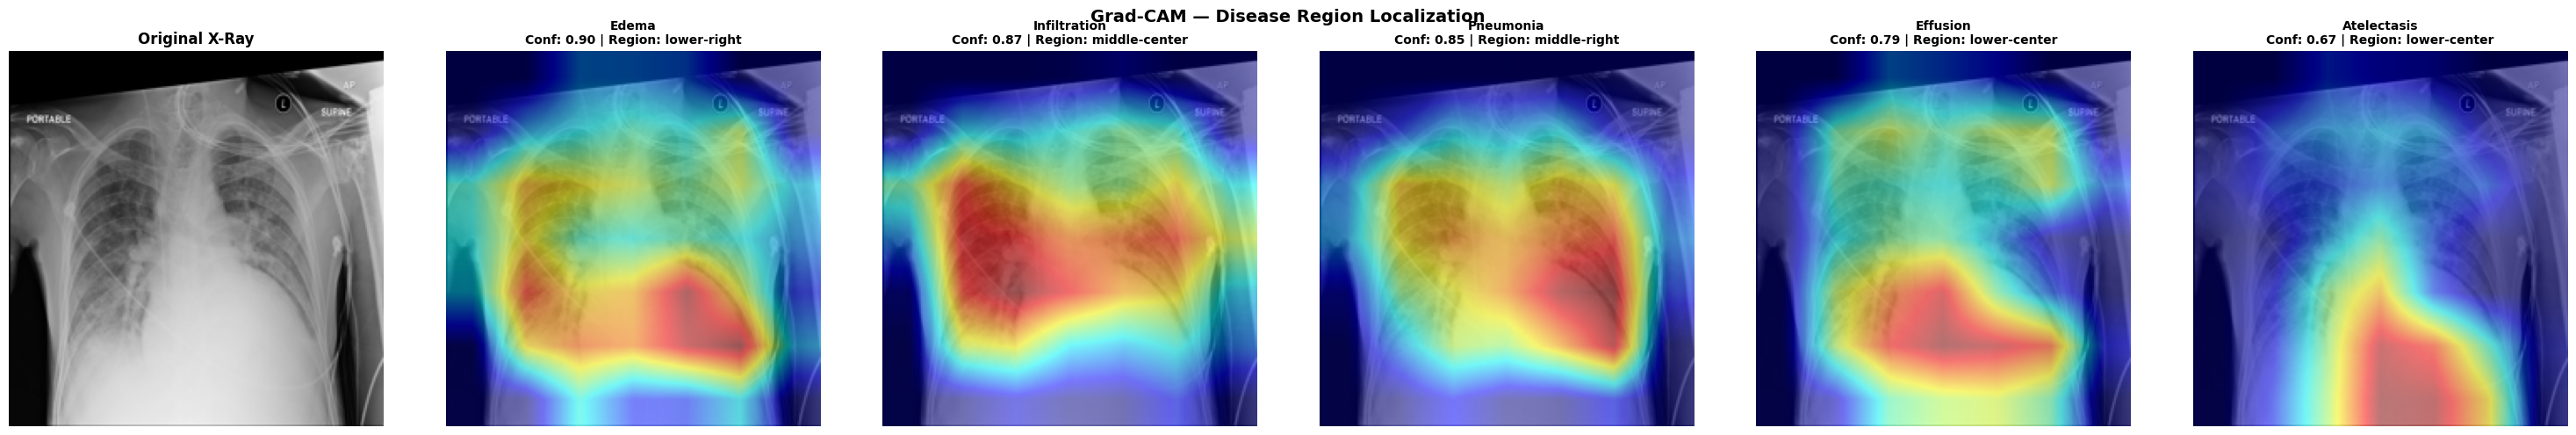


✔ Grad-CAM saved to: /content/drive/MyDrive/gradcam_output.png
✔ Passing heatmap info to Agent 2...
🟡 LANGGRAPH → Grad-CAM complete → Routing to Verification

🟠 LANGGRAPH → Entering Verification Node

[Agent 2 - LLM Verification Agent]
Sending findings to LLM for verification...

Checking for contradictions...
  ✔ No contradictions found

Checking for high risk combinations...
  🔺 High risk combo: Pneumonia + Effusion

Checking low confidence flags...
  ⚠ Recommended dismissal: Atelectasis
  ⚠ Recommended dismissal: Edema

LLM Reasoning: The model's findings do not contain any clinical contradictions, but the combination of Pneumonia and Effusion does indicate a high-risk condition. Given the confidence levels, Atelectasis and Edema are recommended for dismissal. The overall severity remains Severe due to the presence of multiple serious conditions.

───────────────────────────────────────────────────────
Verification : PASSED ✅
Final Severity: Severe
✔ Passing verified report to Agen

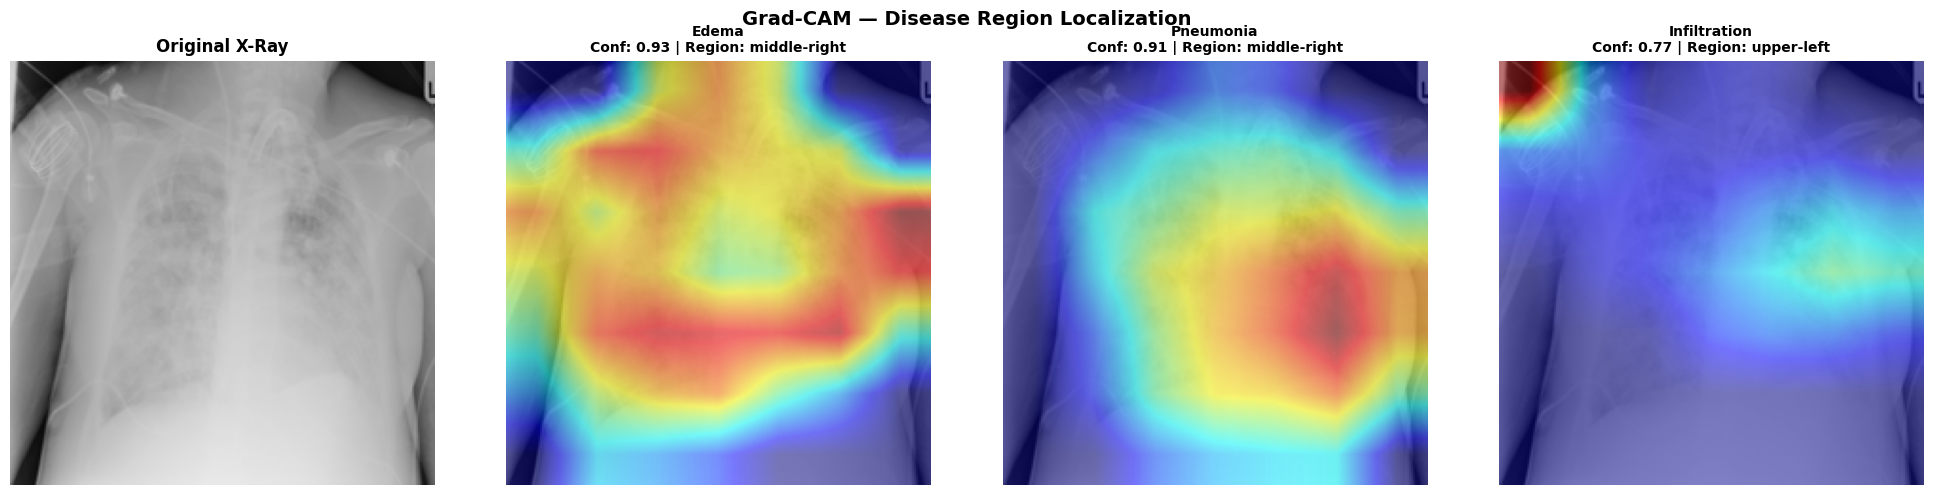


✔ Grad-CAM saved to: /content/drive/MyDrive/gradcam_output.png
✔ Passing heatmap info to Agent 2...
🟡 LANGGRAPH → Grad-CAM complete → Routing to Verification

🟠 LANGGRAPH → Entering Verification Node

[Agent 2 - LLM Verification Agent]
Sending findings to LLM for verification...

Checking for contradictions...
  ✔ No contradictions found

Checking for high risk combinations...
  🔺 High risk combo: Pneumonia + Edema

Checking low confidence flags...
  ⚠ Recommended dismissal: Pneumonia

LLM Reasoning: The presence of both Edema and Pneumonia, particularly with high confidence in Edema, suggests a severe condition. Although Pneumonia has a low confidence flag, the combination with Edema warrants an upgrade in severity. The AI detection model's findings are verified as they do not contain any clinical contradictions, and the severity is adjusted accordingly.

───────────────────────────────────────────────────────
Verification : PASSED ✅
Final Severity: Severe
✔ Passing verified report t

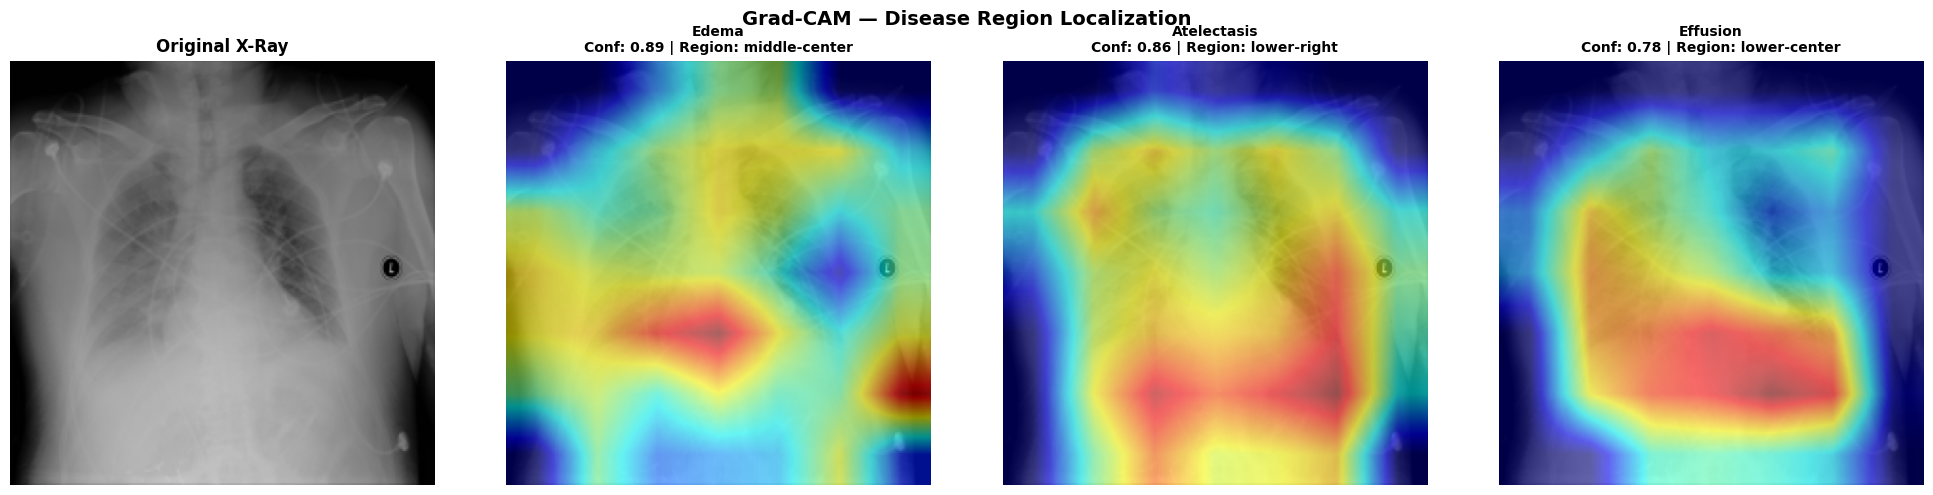


✔ Grad-CAM saved to: /content/drive/MyDrive/gradcam_output.png
✔ Passing heatmap info to Agent 2...
🟡 LANGGRAPH → Grad-CAM complete → Routing to Verification

🟠 LANGGRAPH → Entering Verification Node

[Agent 2 - LLM Verification Agent]
Sending findings to LLM for verification...

Checking for contradictions...
  ✔ No contradictions found

Checking for high risk combinations...
  🔺 High risk combo: Edema + Effusion
  🔺 High risk combo: Atelectasis + Effusion

Checking low confidence flags...
  ✔ All findings retained

LLM Reasoning: The detected conditions of Edema, Atelectasis, and Effusion do not pose any clinical contradictions, but their combinations suggest a high-risk scenario, warranting an upgrade in severity to Severe. The low confidence findings for Edema and Effusion are still above the detection threshold and supported by Grad-CAM heatmaps, so they should not be dismissed. The overall verification passes as there are no contradictions that would make the findings unreliable

Saving img.jpeg to img (1).jpeg

✔ Image uploaded  : img (1).jpeg
✔ Saved to        : /content/img (1).jpeg
🚀 Running full pipeline on your image...


#######################################################
  IMAGE CUSTOM — LANGGRAPH AGENTIC AI SYSTEM
#######################################################
Image: img (1).jpeg

🔵 LANGGRAPH → Entering Detection Node

[Agent 1 - Detection Agent]
Analyzing image: /content/img (1).jpeg

Decision : ABNORMAL
Severity : Moderate

Detected Findings:
  • Mass                      confidence: 0.8885
  • Infiltration              confidence: 0.8010
  • Nodule                    confidence: 0.7851

✔ Passing findings to Grad-CAM...
🔵 LANGGRAPH → Decision: ABNORMAL → Routing to Grad-CAM

🟡 LANGGRAPH → Entering Grad-CAM Node

[Grad-CAM Explainability Module]
  • Mass                      hotspot region: lower-right | intensity: 1.0000
  • Infiltration              hotspot region: upper-left | intensity: 1.0000
  • Nodule                    hotspot re

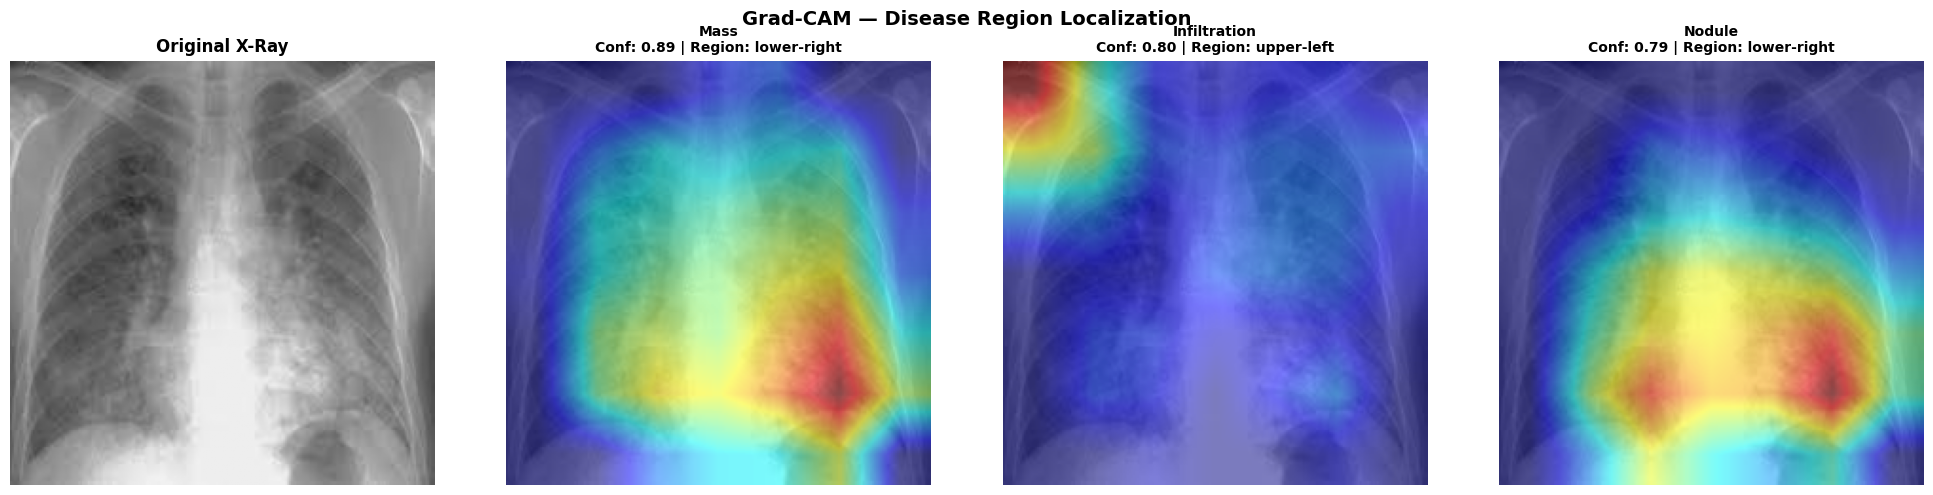


✔ Grad-CAM saved to: /content/drive/MyDrive/gradcam_output.png
✔ Passing heatmap info to Agent 2...
🟡 LANGGRAPH → Grad-CAM complete → Routing to Verification

🟠 LANGGRAPH → Entering Verification Node

[Agent 2 - LLM Verification Agent]
Sending findings to LLM for verification...

Checking for contradictions...
  ✔ No contradictions found

Checking for high risk combinations...
  🔺 High risk combo: Mass + Infiltration
  🔺 High risk combo: Mass + Nodule

Checking low confidence flags...
  ✔ All findings retained

LLM Reasoning: No clinical contradictions were found, but high-risk combinations of Mass with Infiltration and Nodule suggest a severe condition, upgrading the severity from Moderate to Severe. The model's high confidence in these findings supports this decision. The presence of multiple potential diseases in different locations indicates a complex clinical picture.

───────────────────────────────────────────────────────
Verification : PASSED ✅
Final Severity: Severe
✔ Passing

In [ ]:
# Cell 22 — Run LangGraph Pipeline
import random
from google.colab import files
import shutil
import os

# ══════════════════════════════════════════════
# ⚙ YOUR CHOICE — Change this only
# ══════════════════════════════════════════════
UPLOAD_CUSTOM_IMAGE = True   # ← True  = upload from your computer
                               # ← False = only run 5 dataset images
# ══════════════════════════════════════════════

def run_langgraph_pipeline(image_path, image_num):
    print(f"\n{'#'*55}")
    print(f"  IMAGE {image_num} — LANGGRAPH AGENTIC AI SYSTEM")
    print(f"{'#'*55}")
    print(f"Image: {image_path.split('/')[-1]}")

    # ── Initialize state ──
    initial_state = AgentState(
        image_path        = image_path,
        detected          = [],
        decision          = "",
        severity          = "",
        low_conf          = [],
        all_findings      = {},
        raw_probs         = [],
        heatmap_info      = {},
        verified_findings = [],
        contradictions    = [],
        risk_upgrades     = [],
        low_conf_issues   = [],
        verification_pass = True,
        report            = "",
        next_step         = "",
        retry_count       = 0
    )

    # ── Run LangGraph ──
    final_state = app.invoke(initial_state)

    # ── Final Output ──
    print(f"\n{'='*55}")
    print(f"📋 FINAL LANGGRAPH REPORT — IMAGE {image_num}")
    print(f"{'='*55}")
    print(f"Image        : {image_path.split('/')[-1]}")
    print(f"Decision     : {final_state['decision']}")
    print(f"Severity     : {final_state['severity']}")
    print(f"Verification : {'PASSED ✅' if final_state['verification_pass'] else 'FLAGGED ⚠'}")
    print(f"Retries      : {final_state['retry_count']}")
    print(f"\nDetected Findings:")
    for label, conf in final_state["verified_findings"] or final_state["detected"]:
        print(f"  • {label:<25} {conf*100:.1f}%")
    if final_state["heatmap_info"]:
        print(f"\nGrad-CAM Regions:")
        for label, info in final_state["heatmap_info"].items():
            print(f"  • {label:<25} {info['region']}")
    print(f"\n🏥 Diagnostic Report:")
    print(final_state["report"])
    print(f"{'='*55}\n")

    return final_state


# ════════════════════════════════════════════════════════
# ── Run on 5 random dataset images ──
# ════════════════════════════════════════════════════════
print("🚀 Starting LangGraph Agentic AI Pipeline...\n")

random_indices = random.sample(range(len(test_df)), 5)
print(f"Selected images: {random_indices}\n")

all_results = []
for count, i in enumerate(random_indices):
    image_path = test_df.iloc[i]["image_path"]
    result     = run_langgraph_pipeline(image_path, count+1)
    if result.get("heatmap_info"):
        eq = explainability_metric.compute(result, result["heatmap_info"])
    all_results.append(result)
    print("\n")

# ── Summary ──
print("="*55)
print("✅ LANGGRAPH PIPELINE COMPLETE")
print("="*55)
print(f"Total images analyzed : {len(all_results)}")
print(f"\nSummary:")
for i, r in enumerate(all_results):
    print(f"  Image {i+1}: {r['decision']:<10} | Severity: {r['severity']:<10} | Retries: {r['retry_count']}")
print("="*55)


# ════════════════════════════════════════════════════════
# ── Run on YOUR custom uploaded image ──
# ════════════════════════════════════════════════════════
if UPLOAD_CUSTOM_IMAGE:
    print("\n" + "="*55)
    print("📤 CUSTOM IMAGE TEST")
    print("="*55)
    print("Upload your own chest X-ray image (PNG or JPG):")

    uploaded = files.upload()   # ← Colab shows "Choose Files" button here

    if uploaded:
        custom_image_name = list(uploaded.keys())[0]
        clean_path        = f"/content/{custom_image_name}"

        print(f"\n✔ Image uploaded  : {custom_image_name}")
        print(f"✔ Saved to        : {clean_path}")
        print("🚀 Running full pipeline on your image...\n")

        custom_result = run_langgraph_pipeline(clean_path, "CUSTOM")

        if custom_result.get("heatmap_info"):
            print("\n📊 Explainability Score for your image:")
            eq = explainability_metric.compute(custom_result, custom_result["heatmap_info"])

        print("\n✅ Custom image analysis complete!")

    else:
        print("⚠ No image uploaded — skipping custom image test")

else:
    print("\nℹ Custom image test skipped.")
    print("  To upload your own image set UPLOAD_CUSTOM_IMAGE = True at the top of this cell")